# NPE on GALFORM: does the choice of K-band calibration data change the posterior?

Neural posterior estimation (NPE) for the 19 GALFORM physics parameters, trained on the z = 0 rest-frame
K-band luminosity function of the dc-hick2 L800 (P-Millennium) campaign, then applied to three observed K-band LFs:

| Dataset | Survey | Age |
|---|---|---|
| Kochanek et al. 2001 | 2MASS + CfA | old (in GALFORM's calibration set) |
| Cole et al. 2001 | 2dFGRS + 2MASS | old (used in Lacey et al. 2016) |
| Driver et al. 2012 | GAMA | new |

K band is used first because all three datasets measure it, so the comparison is like for like.

**Training set.** Campaign runs 100–399 (batches 2–4), each 64 of the 1024 L800 subvolumes. These were drawn from the
not-ruled-out (NROY) region of history matching, so the network learns the posterior *within that region*
(truncated-prior NPE). Caveat: the NROY region was itself found by fitting r + K LFs (Kochanek K) + HIMF, so it
favours the old data. Section 6 checks whether any posterior piles up against the edge of the training region.

**Method.**
* x = ln φ of the model K LF, evaluated at each dataset's own magnitudes (one network per dataset).
* Noise: each simulated x gets Gaussian noise with that dataset's errors plus a model-discrepancy term
  σ_disc = 0.2 in ln φ (same value as the dc-hick2 pipeline), so the network knows how noisy the data are.
* θ in the design's scaled units [0, 1] (uniform prior), shown in physical units at the end.
* Only the marginal posterior of the parameters the K LF responds to is fitted (Section 5 explains why).

Sources: summaries `.../galform_clustering_calibration/data/campaign/summary_sid*_z0.0000.npz`,
design `.../designs/campaign.json`, observations from `galform/Obs_Data2`.

In [1]:
import json

import numpy as np
import torch
import matplotlib.pyplot as plt
from sbi.neural_nets import posterior_nn
from sbi.utils import BoxUniform

torch.set_num_threads(8)
SEED = 20261029
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

CAL = "/cosma/apps/durham/dc-hick2/galform_clustering_calibration"
OBS = "/cosma/apps/durham/dc-lock1/galform/Obs_Data2"
IVOL_VOLUME = 542.16**3 / 1024  # (Mpc/h)^3; L800 box is 800 Mpc = 542.16 Mpc/h, split into 1024 subvolumes
K_VEGA_TO_AB = 1.870            # AB = Vega + 1.870 (GALFORM's A0-AB offset for UKIRT K is -1.870)
MAG_RANGE = (-23.75, -18.5)     # AB; covered by all three datasets (drops Kochanek's faintest, outlying bin)
SIGMA_DISC = 0.2                # model discrepancy, in ln(phi)
N_TEST = 30                     # runs held out for the coverage test

/cosma/apps/durham/dc-lock1/.venvs/galform_venv/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the training runs
Model LF = counts summed over the 64 subvolumes / (64 × subvolume volume × bin width). Empty bins (some runs have
no galaxies at the bright end) are floored at 0.5 galaxies so ln φ stays finite.

In [2]:
design = json.load(open(f"{CAL}/designs/campaign.json"))
PARAMS = design["param_names"]
units_all = np.array(design["units"])
thetas_all = np.array(design["thetas"])

def model_lnphi(path):
    z = np.load(path)
    counts = z["lf_mag_UKIRT-K_r_tot_ext"].sum(axis=0)  # sum over the subvolumes
    edges = z["lf_edges"]
    volume = z["lf_mag_UKIRT-K_r_tot_ext"].shape[0] * IVOL_VOLUME
    return 0.5 * (edges[1:] + edges[:-1]), np.log(np.maximum(counts, 0.5) / (volume * np.diff(edges)))

SIDS = np.arange(100, 400)
lnphi_model = []
for sid in SIDS:
    mag_model, lnphi = model_lnphi(f"{CAL}/data/campaign/summary_sid{sid:05d}_z0.0000.npz")
    lnphi_model.append(lnphi)
lnphi_model = np.array(lnphi_model)
units = units_all[SIDS]
print(f"{len(SIDS)} runs, {len(PARAMS)} parameters, model LF on {len(mag_model)} bins")

300 runs, 19 parameters, model LF on 48 bins


## 2. Observed K-band LFs, in the model's conventions
All converted to AB, M − 5 log h, ln φ with φ per mag, and σ in ln φ.

Kochanek+01        21 bins, -23.63 to -18.63, median sigma_ln 0.46
Cole+01            21 bins, -23.63 to -18.63, median sigma_ln 0.09
Driver+12 (GAMA)   10 bins, -23.25 to -18.75, median sigma_ln 0.04


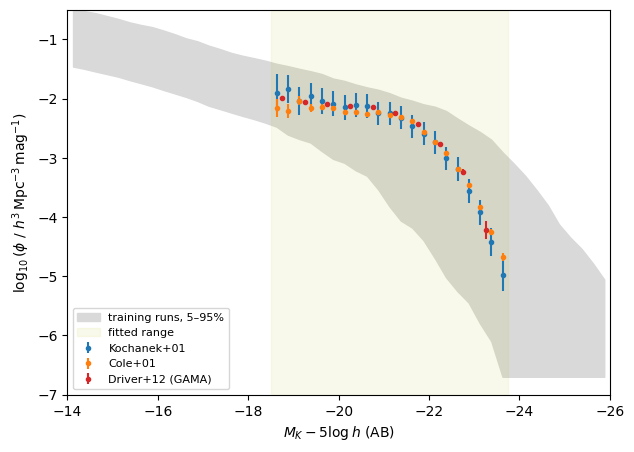

In [3]:
def load_kochanek():
    mag, logphi, err = np.loadtxt(f"{OBS}/lfK_Kochanek2001.data", unpack=True)  # Vega, log10 phi, error in log10
    return mag + K_VEGA_TO_AB, logphi * np.log(10), err * np.log(10)

def load_cole():
    mag, phi, err = np.loadtxt(f"{OBS}/lfJK_Cole2001.data", usecols=(0, 3, 4), unpack=True)  # Vega
    ok = phi > 0
    return mag[ok] + K_VEGA_TO_AB, np.log(phi[ok]), err[ok] / phi[ok]

def load_driver():
    mag, phi, err = np.loadtxt(f"{OBS}/lfk_z0_driver12.data", usecols=(0, 1, 2), unpack=True)  # AB, per 0.5 mag
    ok = phi > 0
    return mag[ok], np.log(phi[ok] / 0.5), err[ok] / phi[ok]

DATASETS = {}
for name, loader in (("Kochanek+01", load_kochanek), ("Cole+01", load_cole), ("Driver+12 (GAMA)", load_driver)):
    mag, lnphi, sigma = loader()
    use = (mag > MAG_RANGE[0]) & (mag < MAG_RANGE[1])
    DATASETS[name] = {"mag": mag[use], "lnphi": lnphi[use], "sigma": sigma[use]}
    print(f"{name:18s} {use.sum():2d} bins, {mag[use].min():.2f} to {mag[use].max():.2f}, "
          f"median sigma_ln {np.median(sigma[use]):.2f}")

COLOURS = {"Kochanek+01": "C0", "Cole+01": "C1", "Driver+12 (GAMA)": "C3"}

fig, ax = plt.subplots(figsize=(7, 5))
lo, hi = np.percentile(lnphi_model, [5, 95], axis=0)
ax.fill_between(mag_model, lo / np.log(10), hi / np.log(10), color="0.85", label="training runs, 5–95%")
for name, d in DATASETS.items():
    ax.errorbar(d["mag"], d["lnphi"] / np.log(10), yerr=d["sigma"] / np.log(10), fmt="o", ms=3,
                color=COLOURS[name], label=name)
ax.set_xlim(-14, -26)
ax.set_ylim(-7, -0.5)
ax.axvspan(*MAG_RANGE, color="y", alpha=0.08, label="fitted range")
ax.set_xlabel(r"$M_K - 5\log h$ (AB)")
ax.set_ylabel(r"$\log_{10}(\phi\ /\ h^3\,{\rm Mpc}^{-3}\,{\rm mag}^{-1})$")
ax.legend(fontsize=8)

## 3. Sample variance from the replicate runs
sid 183 and 90183 have the same parameters but a different draw of 64 subvolumes (same for 81 / 90081). If the
difference between them is small next to the data errors, simulation noise can be ignored next to the injected
noise.

In [4]:
for sid in (81, 183):
    _, a = model_lnphi(f"{CAL}/data/campaign/summary_sid{sid:05d}_z0.0000.npz")
    _, b = model_lnphi(f"{CAL}/data/campaign_replicates/summary_sid{90000 + sid:05d}_z0.0000.npz")
    use = (mag_model > MAG_RANGE[0]) & (mag_model < MAG_RANGE[1])
    print(f"sid {sid}: rms ln(phi) difference between subvolume draws = {np.std(a[use] - b[use]):.3f} "
          f"(max {np.abs(a[use] - b[use]).max():.3f})")
for name, d in DATASETS.items():
    print(f"{name:18s} smallest data sigma_ln = {d['sigma'].min():.3f}, with sigma_disc: "
          f"{np.sqrt(d['sigma'].min()**2 + SIGMA_DISC**2):.3f}")

sid 81: rms ln(phi) difference between subvolume draws = 0.030 (max 0.078)
sid 183: rms ln(phi) difference between subvolume draws = 0.025 (max 0.083)
Kochanek+01        smallest data sigma_ln = 0.461, with sigma_disc: 0.502
Cole+01            smallest data sigma_ln = 0.040, with sigma_disc: 0.204
Driver+12 (GAMA)   smallest data sigma_ln = 0.030, with sigma_disc: 0.202


## 4. How much do the parameters affect the K LF inside the training region?
Before any neural network: a cross-validated linear (ridge) regression of each parameter on the model K LF.
R² ≈ 0 means the LF barely tracks that parameter across the training runs; the batch-1 uniform runs are shown for
comparison, because the training region was already selected to fit the K LF.

In [5]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import cross_val_predict

in_range = (mag_model > MAG_RANGE[0]) & (mag_model < MAG_RANGE[1])
def lnphi_of(sid):
    return model_lnphi(f"{CAL}/data/campaign/summary_sid{sid:05d}_z0.0000.npz")[1][in_range]

r2 = {}
for label, sids in (("training (NROY) runs", SIDS), ("uniform batch-1 runs", np.arange(100))):
    X = np.array([lnphi_of(s) for s in sids])
    X = (X - X.mean(0)) / X.std(0)
    pred = [cross_val_predict(RidgeCV(alphas=np.logspace(-3, 3, 13)), X, units_all[sids, i], cv=10) for i in range(len(PARAMS))]
    r2[label] = [1 - np.mean((p - units_all[sids, i])**2) / units_all[sids, i].var() for i, p in enumerate(pred)]
print(f"{'parameter':24s}" + "".join(f"{k:>24s}" for k in r2))
for i, p in enumerate(PARAMS):
    print(f"{p:24s}" + "".join(f"{v[i]:24.2f}" for v in r2.values()))

parameter                   training (NROY) runs    uniform batch-1 runs
nu_sf                                      -0.04                   -0.08
fburst                                      0.00                   -0.03
fellip                                     -0.00                   -0.02
stabledisk                                  0.02                    0.00
vhotdisk                                    0.04                    0.05
vhotburst                                   0.07                   -0.02
alphahot                                    0.29                    0.09
alpha_reheat                               -0.01                    0.11
vcut                                       -0.02                   -0.11
zcut                                       -0.02                   -0.03
alpha_cool                                  0.07                    0.54
F_SMBH                                     -0.04                   -0.01
alphastar                                  -0.01   

## 5. Train the networks
With ~270 runs a flow cannot learn a 19-dimensional posterior (it memorises the training points and comes out
over-confident), so we fit the **marginal** posterior of `FIT_PARAMS`, the parameters the K LF responds to.
NPE on a subset of θ is still exact for that subset: the other parameters are marginalised over automatically.

Training details:
* runs are split into train / validation / test **by run**, so early stopping sees runs it has never trained on;
* fresh noise (σ² = σ_data² + σ_disc²) is drawn every epoch, so noise cannot be memorised;
* `N_ENSEMBLE` networks with different seeds are averaged, which reduces over-confidence;
* a control network is trained with the LFs shuffled between runs. It has no information, so its shrinkage
  is the baseline the real networks must beat.

In [6]:
from sbi.inference.posteriors import DirectPosterior

FIT_PARAMS = ["alphahot", "vhotdisk", "vhotburst", "alpha_cool", "alpha_reheat"]
N_ENSEMBLE = 5
N_VAL = 30
fit = [PARAMS.index(p) for p in FIT_PARAMS]
theta_fit = units[:, fit]
prior = BoxUniform(low=torch.zeros(len(fit)), high=torch.ones(len(fit)))

perm = rng.permutation(len(SIDS))
test_idx, val_idx, train_idx = perm[:N_TEST], perm[N_TEST:N_TEST + N_VAL], perm[N_TEST + N_VAL:]
T = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)

def sim_at(d, idx):
    return np.array([np.interp(d["mag"], mag_model, lnphi_model[i]) for i in idx])

def add_noise(x, d):
    return x + rng.normal(size=x.shape) * np.sqrt(d["sigma"]**2 + SIGMA_DISC**2)

def train_one(x_runs, theta_runs, d, seed, patience=50):
    # x_runs/theta_runs: one row per run; train/val split by run; fresh noise each epoch
    torch.manual_seed(seed)
    tr, va = train_idx, val_idx
    x0 = add_noise(np.repeat(x_runs[tr], 20, 0), d)
    net = posterior_nn(model="nsf", hidden_features=32, num_transforms=3)(T(np.repeat(theta_runs[tr], 20, 0)), T(x0))
    opt = torch.optim.Adam(net.parameters(), lr=5e-4, weight_decay=1e-4)
    x_val, t_val = T(add_noise(np.repeat(x_runs[va], 50, 0), d)), T(np.repeat(theta_runs[va], 50, 0))
    best, bad, state = np.inf, 0, None
    while bad < patience:
        x, t = T(add_noise(np.repeat(x_runs[tr], 4, 0), d)), T(np.repeat(theta_runs[tr], 4, 0))
        net.train()
        for b in torch.randperm(len(t)).split(128):
            opt.zero_grad()
            net.loss(t[b], x[b]).mean().backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = net.loss(t_val, x_val).mean().item()
        if v < best - 1e-3:
            best, bad, state = v, 0, {k: p.clone() for k, p in net.state_dict().items()}
        else:
            bad += 1
    net.load_state_dict(state)
    return DirectPosterior(posterior_estimator=net, prior=prior)

def sample_ensemble(members, x_o, n):
    # equal-weight mixture of the ensemble members
    return np.concatenate([m.sample((n // len(members),), x=T(x_o), show_progress_bars=False).numpy() for m in members])

ensembles, controls = {}, {}
for name, d in DATASETS.items():
    x_runs = sim_at(d, np.arange(len(SIDS)))
    ensembles[name] = [train_one(x_runs, theta_fit, d, SEED + k) for k in range(N_ENSEMBLE)]
    shuffled = x_runs[rng.permutation(len(x_runs))]  # control: break the link between LF and parameters
    controls[name] = [train_one(shuffled, theta_fit, d, SEED + 100 + k) for k in range(N_ENSEMBLE)]
    print(f"trained {name}: {N_ENSEMBLE} networks + {N_ENSEMBLE} shuffled controls")

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


trained Kochanek+01: 5 networks + 5 shuffled controls


trained Cole+01: 5 networks + 5 shuffled controls


trained Driver+12 (GAMA): 5 networks + 5 shuffled controls


## 6. Check the networks on held-out runs
For each held-out run, its LF (with a fresh noise draw) is treated as data.
* **Coverage**: fraction of runs whose true value lies in the central 68% (95%) interval. Should be ≈ 0.68 (0.95);
  with 30 test runs the uncertainty is about ±0.09 (±0.04). Much lower means over-confident.
* **Shrinkage**: 1 − posterior variance / variance of the training runs. Compare with the shuffled control: only
  shrinkage **above the control** is information from the LF.

In [7]:
N_POST = 1000
train_var = theta_fit[train_idx].var(axis=0)

def held_out_check(members, d):
    x_test = add_noise(sim_at(d, test_idx), d)
    ranks, shrink = [], []
    for x_o, true in zip(x_test, theta_fit[test_idx]):
        s = sample_ensemble(members, x_o, N_POST)
        ranks.append((s < true).mean(axis=0))
        shrink.append(1 - s.var(axis=0) / train_var)
    ranks = np.array(ranks)
    return (((ranks > 0.16) & (ranks < 0.84)).mean(0), ((ranks > 0.025) & (ranks < 0.975)).mean(0), np.mean(shrink, 0))

checks = {name: (held_out_check(ensembles[name], d), held_out_check(controls[name], d)) for name, d in DATASETS.items()}
for name, ((c68, c95, sh), (_, _, sh0)) in checks.items():
    print(f"\n{name}")
    print(f"  {'parameter':14s} {'cov68':>6s} {'cov95':>6s} {'shrink':>7s} {'control':>8s} {'information':>12s}")
    for i, p in enumerate(FIT_PARAMS):
        print(f"  {p:14s} {c68[i]:6.2f} {c95[i]:6.2f} {sh[i]:7.2f} {sh0[i]:8.2f} {sh[i] - sh0[i]:12.2f}")

/cosma/apps/durham/dc-lock1/.venvs/galform_venv/lib64/python3.9/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at /pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2264.)
  outputs, _ = torch.triangular_solve(



Kochanek+01
  parameter       cov68  cov95  shrink  control  information
  alphahot         0.53   0.90    0.31     0.19         0.12
  vhotdisk         0.40   0.93    0.20     0.17         0.03
  vhotburst        0.53   0.83    0.14     0.08         0.07
  alpha_cool       0.47   0.90    0.27     0.17         0.11
  alpha_reheat     0.63   0.93    0.16     0.23        -0.07

Cole+01
  parameter       cov68  cov95  shrink  control  information
  alphahot         0.53   0.90    0.32     0.20         0.12
  vhotdisk         0.37   0.90    0.21     0.15         0.06
  vhotburst        0.50   0.83    0.17     0.07         0.10
  alpha_cool       0.50   0.90    0.24     0.17         0.07
  alpha_reheat     0.63   0.93    0.17     0.26        -0.09

Driver+12 (GAMA)
  parameter       cov68  cov95  shrink  control  information
  alphahot         0.50   0.97    0.30     0.17         0.13
  vhotdisk         0.30   0.90    0.19     0.13         0.06
  vhotburst        0.47   0.83    0.16     0.

## 7. Posteriors from the real data
Grey: distribution of the training runs (the effective prior). Dotted: the shuffled control given the same data,
i.e. what the posterior looks like with no information. A posterior piling up against the edge of the grey region is
cut off by the training region rather than by the data.

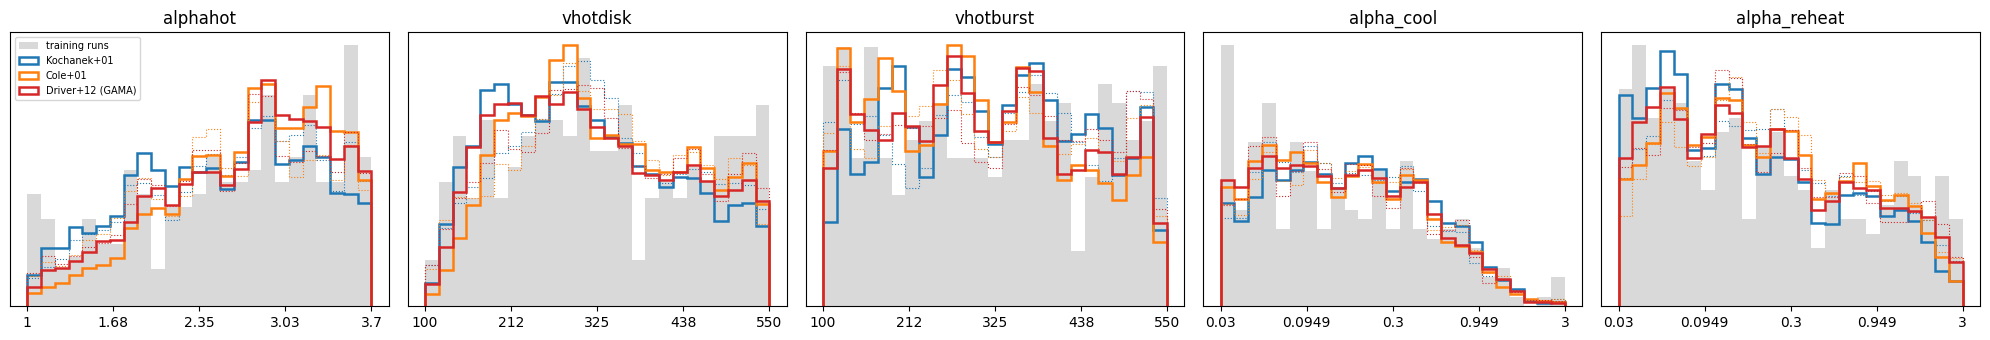

In [8]:
N_POST_OBS = 20000
samples = {name: sample_ensemble(ensembles[name], d["lnphi"], N_POST_OBS) for name, d in DATASETS.items()}
control_samples = {name: sample_ensemble(controls[name], d["lnphi"], N_POST_OBS) for name, d in DATASETS.items()}

def to_physical(u, i):
    # each parameter is either linear or log10-uniform in its units; pick whichever reproduces the design exactly
    a = np.polyfit(units_all[:, i], thetas_all[:, i], 1)
    if np.allclose(np.polyval(a, units_all[:, i]), thetas_all[:, i], rtol=1e-6):
        return np.polyval(a, u)
    b = np.polyfit(units_all[:, i], np.log10(thetas_all[:, i]), 1)
    return 10 ** np.polyval(b, u)

fig, axes = plt.subplots(1, len(FIT_PARAMS), figsize=(4 * len(FIT_PARAMS), 3.5))
bins = np.linspace(0, 1, 26)
for j, ax in enumerate(axes):
    i = fit[j]
    ax.hist(theta_fit[train_idx, j], bins=bins, density=True, color="0.85", label="training runs")
    for name in DATASETS:
        ax.hist(samples[name][:, j], bins=bins, density=True, histtype="step", lw=1.8, color=COLOURS[name], label=name)
        ax.hist(control_samples[name][:, j], bins=bins, density=True, histtype="step", lw=0.8, ls=":", color=COLOURS[name])
    ticks = np.linspace(0, 1, 5)
    ax.set_xticks(ticks, [f"{to_physical(t, i):.3g}" for t in ticks])
    ax.set_title(FIT_PARAMS[j])
    ax.set_yticks([])
axes[0].legend(fontsize=7)
fig.tight_layout()

### Summary in physical units
Median and 16–84% range. Shift = difference between the Driver (GAMA) median and each old dataset's median, in units
of their combined posterior width.

In [9]:
names = list(DATASETS)
g = "Driver+12 (GAMA)"
print(f"{'parameter':14s}" + "".join(f"{n:>28s}" for n in names) + "   GAMA shift vs Koch / Cole")
for j, p in enumerate(FIT_PARAMS):
    row, med, wid = f"{p:14s}", {}, {}
    for n in names:
        q16, q50, q84 = np.percentile(samples[n][:, j], [16, 50, 84])
        lo, mid, hi = to_physical(np.array([q16, q50, q84]), fit[j])
        row += f"   {mid:8.3g} [{lo:7.3g},{hi:7.3g}]"
        med[n], wid[n] = q50, (q84 - q16) / 2
    shifts = [(med[g] - med[o]) / np.hypot(wid[g], wid[o]) for o in ("Kochanek+01", "Cole+01")]
    print(row + f"   {shifts[0]:+5.1f} / {shifts[1]:+5.1f} sigma")

parameter                      Kochanek+01                     Cole+01            Driver+12 (GAMA)   GAMA shift vs Koch / Cole
alphahot             2.57 [   1.76,   3.27]       2.83 [   2.07,   3.37]       2.79 [   1.93,   3.35]    +0.2 /  -0.0 sigma
vhotdisk              297 [    188,    444]        316 [    212,    464]        307 [    194,    458]    +0.1 /  -0.0 sigma
vhotburst             326 [    187,    462]        292 [    164,    442]        307 [    169,    460]    -0.1 /  +0.1 sigma
alpha_cool          0.173 [ 0.0576,  0.521]      0.144 [ 0.0521,  0.459]      0.147 [ 0.0513,  0.472]    -0.1 /  +0.0 sigma
alpha_reheat        0.141 [ 0.0497,   0.76]      0.187 [ 0.0583,  0.861]      0.174 [ 0.0532,  0.898]    +0.1 /  -0.0 sigma


### Which training runs fit each dataset best?
A direct check that needs no network: χ² of every run against each dataset (errors include σ_disc), the 5 best runs
plotted, and the parameter values of the best 10% of runs. If the old and GAMA datasets prefer different physics,
their best-fitting runs should sit in different places.

best 10% of runs (30) shared by all three datasets: 20
parameter              Kochanek+01             Cole+01    Driver+12 (GAMA)   (median of best 10%, all runs)
alphahot                      2.26                 2.2                2.34   2.73
vhotdisk                       315                 322                 307   316
vhotburst                      290                 277                 306   333
alpha_cool                   0.105              0.0994               0.117   0.132
alpha_reheat                0.0891               0.108               0.123   0.175


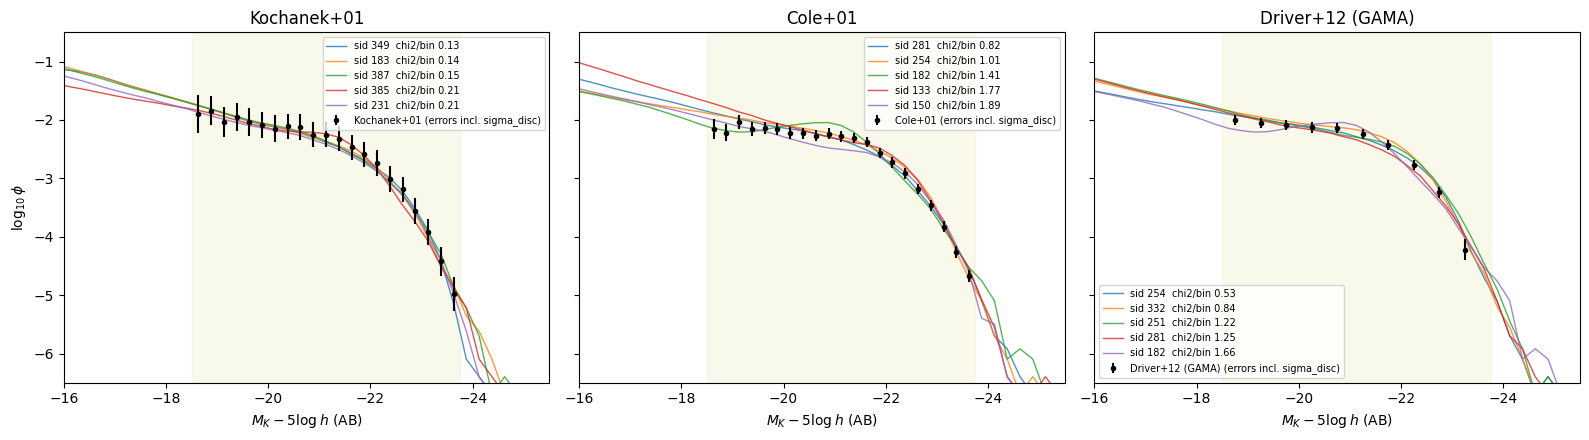

In [10]:
chi2 = {}
for name, d in DATASETS.items():
    resid = sim_at(d, np.arange(len(SIDS))) - d["lnphi"]
    chi2[name] = np.sum(resid**2 / (d["sigma"]**2 + SIGMA_DISC**2), axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, d) in zip(axes, DATASETS.items()):
    for i in np.argsort(chi2[name])[:5]:
        ax.plot(mag_model, lnphi_model[i] / np.log(10), lw=1, alpha=0.8,
                label=f"sid {SIDS[i]}  chi2/bin {chi2[name][i] / len(d['mag']):.2f}")
    ax.errorbar(d["mag"], d["lnphi"] / np.log(10), yerr=np.hypot(d["sigma"], SIGMA_DISC) / np.log(10), fmt="o",
                ms=3, color="k", label=f"{name} (errors incl. sigma_disc)")
    ax.axvspan(*MAG_RANGE, color="y", alpha=0.08)
    ax.set_xlim(-16, -25.5)
    ax.set_ylim(-6.5, -0.5)
    ax.set_title(name)
    ax.set_xlabel(r"$M_K - 5\log h$ (AB)")
    ax.legend(fontsize=7)
axes[0].set_ylabel(r"$\log_{10}\phi$")
fig.tight_layout()

best = {name: np.argsort(c)[:len(SIDS) // 10] for name, c in chi2.items()}
overlap = len(set(best["Kochanek+01"]) & set(best["Cole+01"]) & set(best["Driver+12 (GAMA)"]))
print(f"best 10% of runs ({len(SIDS) // 10}) shared by all three datasets: {overlap}")
print(f"{'parameter':14s}" + "".join(f"{n:>20s}" for n in DATASETS) + "   (median of best 10%, all runs)")
for j, p in enumerate(FIT_PARAMS):
    print(f"{p:14s}" + "".join(f"{to_physical(np.median(theta_fit[best[n], j]), fit[j]):20.3g}" for n in DATASETS)
          + f"   {to_physical(np.median(theta_fit[:, j]), fit[j]):.3g}")

## Next steps
* Add b_J (Norberg+02, old only) and r (Driver+12, GAMA only) to see how much each band adds.
* Tully-Fisher (part 4): needs `vdisk` and magnitudes from the raw `galaxies.hdf5`, not in these summaries.
* The training region was chosen to fit the K LF, so inside it the K LF carries little information (Section 4).
  The dataset comparison needs runs spread wider: the 100 uniform batch-1 runs (from a different distribution, so they
  need the proposal correction) or the 688 archived L800 runs.